# Day 045 | Naive Bayes Classifier

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** YYYY-MM-DD  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Bayes' Theorem | Updates probability with new evidence | P(landslide \| heavy rain, steep slope) |
| Naive assumption | Features are independent given the class | Slope angle and rainfall treated independently |
| GaussianNB | Naive Bayes for continuous features | Classifying hazard level from numeric measurements |
| Prior probability | Base rate of each class | How often each risk level occurs historically |
| Likelihood | P(feature \| class) | Distribution of slope angles for high-risk sites |
| Posterior probability | Updated belief after seeing features | Final risk prediction given all measurements |
| Independence assumption | When it helps vs hurts | Correlated features reduce NB accuracy |
| Comparison with Logistic Regression | Two probabilistic classifiers | Which works better for hazard classification |

---

## Our Geotechnical Problem

**Geotechnical Hazard Report Classification**

After site investigations, engineers classify locations into risk levels: **High**, **Medium**, or **Low**. This classification depends on multiple factors measured during field surveys:

- **Slope angle:** Steeper slopes = higher landslide risk
- **Rainfall:** More precipitation = more pore water pressure
- **Soil saturation:** Higher saturation = weaker soil
- **Vegetation cover:** More vegetation = better root reinforcement
- **Clay content:** Higher clay = more sensitive to moisture changes

Can we build a fast, probabilistic classifier that assigns risk levels to new sites?

---

## Part 1: Bayes' Theorem Intuition

**Bayes' Theorem** answers: given what we observe, what is the probability of each class?

```
P(Risk=High | features) = P(features | Risk=High) * P(Risk=High)
                          ────────────────────────────────────────────
                                      P(features)
```

In plain English:
- **Prior** `P(Risk=High)`: How common are high-risk sites in general? (e.g., 25%)
- **Likelihood** `P(features | Risk=High)`: Among known high-risk sites, how common are these feature values?
- **Posterior** `P(Risk=High | features)`: Given these measurements, how likely is high risk?

The **"naive"** part: we assume all features are **independent** given the class. This simplifies the math enormously:

```
P(slope, rain, sat | High) = P(slope | High) * P(rain | High) * P(sat | High)
```

This assumption is rarely true in practice (slope and saturation are correlated!), but Naive Bayes often works surprisingly well despite this simplification.

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS AND SETUP
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

np.random.seed(45)
print("Libraries loaded successfully.")
print("Today: Naive Bayes for geotechnical hazard classification.")

Libraries loaded successfully.
Today: Naive Bayes for geotechnical hazard classification.


---

## Part 2: Generate Synthetic Hazard Data

We create 80 site investigation records with 5 numeric features and a 3-class risk label.

In [2]:
# ─────────────────────────────────────────────────────
# GENERATE SYNTHETIC HAZARD DATA (80 sites)
# ─────────────────────────────────────────────────────

n_samples = 80

# Generate features with class-dependent distributions
# High risk: steep slopes, heavy rain, high saturation, low vegetation, high clay
# Low risk:  gentle slopes, light rain, low saturation, high vegetation, low clay

data = []
classes = ['Low'] * 28 + ['Medium'] * 28 + ['High'] * 24

for risk in classes:
    if risk == 'Low':
        slope = np.random.normal(12, 4)
        rain = np.random.normal(50, 15)
        sat = np.random.normal(30, 10)
        veg = np.random.normal(75, 10)
        clay = np.random.normal(15, 5)
    elif risk == 'Medium':
        slope = np.random.normal(25, 5)
        rain = np.random.normal(100, 20)
        sat = np.random.normal(55, 12)
        veg = np.random.normal(50, 12)
        clay = np.random.normal(30, 8)
    else:  # High
        slope = np.random.normal(38, 5)
        rain = np.random.normal(160, 25)
        sat = np.random.normal(78, 8)
        veg = np.random.normal(25, 10)
        clay = np.random.normal(45, 8)
    
    # Clip to realistic ranges
    slope = np.clip(slope, 2, 60)
    rain = np.clip(rain, 10, 250)
    sat = np.clip(sat, 5, 100)
    veg = np.clip(veg, 5, 95)
    clay = np.clip(clay, 2, 70)
    
    data.append([round(slope, 1), round(rain, 1), round(sat, 1),
                 round(veg, 1), round(clay, 1), risk])

df = pd.DataFrame(data, columns=['slope_angle', 'rainfall_mm', 'soil_saturation',
                                  'vegetation_cover', 'clay_content', 'risk_level'])

# Shuffle
df = df.sample(frac=1, random_state=45).reset_index(drop=True)

# Save
df.to_csv('hazard_data.csv', index=False)

print(f"Dataset: {df.shape[0]} sites, {df.shape[1]} columns")
print(f"\nClass distribution:")
print(df['risk_level'].value_counts().to_string())
print(f"\nFirst 5 rows:")
df.head()

Dataset: 80 sites, 6 columns

Class distribution:
risk_level
Medium    28
Low       28
High      24

First 5 rows:


,slope_angle,rainfall_mm,soil_saturation,vegetation_cover,clay_content,risk_level
0,13.3,63.7,49.1,63.0,27.8,Medium
1,4.8,52.0,47.6,69.7,19.9,Low
2,11.0,76.5,24.1,65.9,16.4,Low
3,7.9,58.8,33.7,50.9,19.8,Low
4,22.6,81.5,54.4,63.1,28.6,Medium


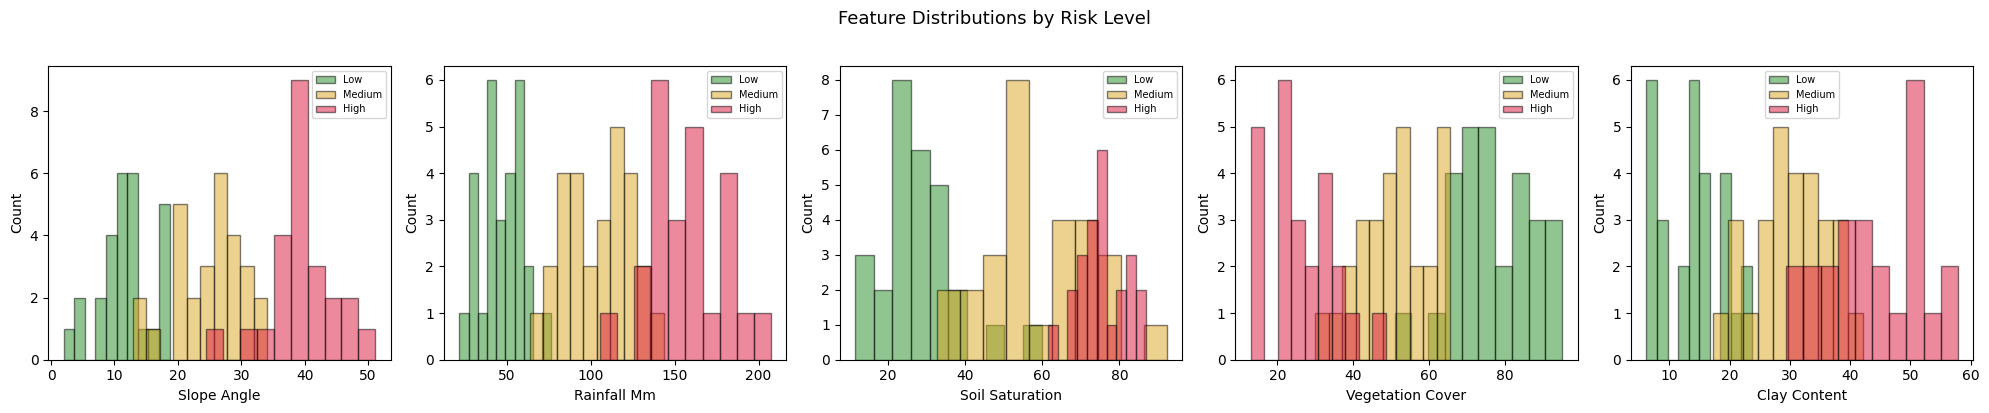

Notice how each feature has different distributions per class.
GaussianNB fits a normal distribution to each feature for each class.


In [3]:
# ─────────────────────────────────────────────────────
# VISUALIZE FEATURE DISTRIBUTIONS BY CLASS
# ─────────────────────────────────────────────────────

features = ['slope_angle', 'rainfall_mm', 'soil_saturation',
            'vegetation_cover', 'clay_content']
colors = {'Low': 'forestgreen', 'Medium': 'goldenrod', 'High': 'crimson'}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, feat in zip(axes, features):
    for risk, color in colors.items():
        subset = df[df['risk_level'] == risk][feat]
        ax.hist(subset, bins=10, alpha=0.5, color=color, label=risk, edgecolor='k')
    ax.set_xlabel(feat.replace('_', ' ').title())
    ax.set_ylabel('Count')
    ax.legend(fontsize=7)

plt.suptitle('Feature Distributions by Risk Level', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
print("Notice how each feature has different distributions per class.")
print("GaussianNB fits a normal distribution to each feature for each class.")

---

## Part 3: How GaussianNB Works

For each class *c* and each feature *x_i*, GaussianNB estimates:
- The **mean** and **variance** of that feature within that class
- This defines a Gaussian (bell curve) for `P(x_i | class=c)`

To predict a new sample, it computes:
1. For each class: multiply the prior by all feature likelihoods
2. Pick the class with the highest posterior probability

**Speed advantage:** GaussianNB only needs to estimate 2 parameters (mean, variance) per feature per class. For 5 features and 3 classes = 30 parameters total. Very fast!

In [4]:
# ─────────────────────────────────────────────────────
# PREPARE DATA
# ─────────────────────────────────────────────────────

X = df[features]
y = df['risk_level']

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # High=0, Low=1, Medium=2
print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=45, stratify=y_encoded
)

print(f"\nTraining: {len(X_train)} samples")
print(f"Test:     {len(X_test)} samples")
print(f"\nNote: GaussianNB does NOT require feature scaling!")
print("It estimates mean/variance per feature per class — scale does not matter.")

Label mapping: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}

Training: 60 samples
Test:     20 samples

Note: GaussianNB does NOT require feature scaling!
It estimates mean/variance per feature per class — scale does not matter.


---

## Part 4: Train GaussianNB and Inspect Learned Parameters

In [5]:
# ─────────────────────────────────────────────────────
# TRAIN GAUSSIAN NAIVE BAYES
# ─────────────────────────────────────────────────────

gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Inspect learned parameters
print("Learned Parameters:")
print(f"\nPrior probabilities (class frequencies):")
for cls, prior in zip(le.classes_, gnb.class_prior_):
    print(f"  P({cls:6s}) = {prior:.3f}")

print(f"\nLearned means (mu) per class per feature:")
means_df = pd.DataFrame(gnb.theta_, columns=features, index=le.classes_)
print(means_df.round(1).to_string())

print(f"\nLearned variances (sigma^2) per class per feature:")
var_df = pd.DataFrame(gnb.var_, columns=features, index=le.classes_)
print(var_df.round(1).to_string())

print("\nInterpretation: High-risk sites have mean slope=37.6, rain=157.3, etc.")
print("These means and variances define the Gaussian likelihood for each feature.")

Learned Parameters:

Prior probabilities (class frequencies):
  P(High  ) = 0.300
  P(Low   ) = 0.350
  P(Medium) = 0.350

Learned means (mu) per class per feature:
        slope_angle  rainfall_mm  soil_saturation  vegetation_cover  clay_content
High           37.9        153.1             75.3              24.4          43.1
Low            11.5         46.7             26.7              77.6          14.4
Medium         24.8        103.9             59.5              52.3          30.3

Learned variances (sigma^2) per class per feature:
        slope_angle  rainfall_mm  soil_saturation  vegetation_cover  clay_content
High           24.2        542.0             27.6              46.3          58.4
Low            19.7        184.5             68.6             122.8          28.0
Medium         16.8        422.0            198.1              74.4          39.4

Interpretation: High-risk sites have mean slope=37.6, rain=157.3, etc.
These means and variances define the Gaussian likelihoo

Gaussian Naive Bayes Results:
  Train accuracy: 1.000
  Test accuracy:  1.000

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         6
         Low       1.00      1.00      1.00         7
      Medium       1.00      1.00      1.00         7

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



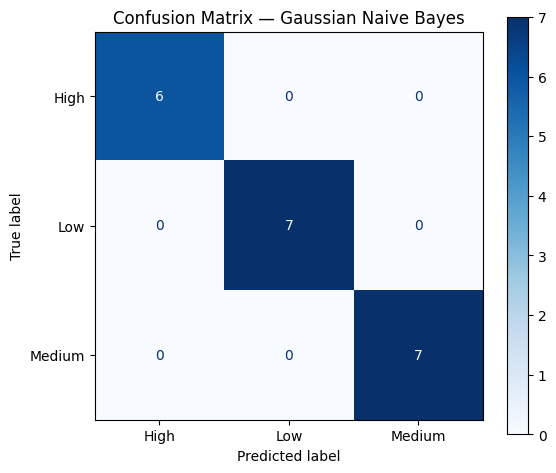

In [6]:
# ─────────────────────────────────────────────────────
# EVALUATE NAIVE BAYES
# ─────────────────────────────────────────────────────

y_pred_nb = gnb.predict(X_test)

print("Gaussian Naive Bayes Results:")
print(f"  Train accuracy: {gnb.score(X_train, y_train):.3f}")
print(f"  Test accuracy:  {accuracy_score(y_test, y_pred_nb):.3f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_nb,
                            target_names=le.classes_))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    gnb, X_test, y_test,
    display_labels=le.classes_,
    cmap='Blues', ax=ax
)
ax.set_title('Confusion Matrix — Gaussian Naive Bayes')
plt.tight_layout()
plt.show()

---

## Part 5: Probability Predictions — NB Gives Confidence!

Unlike some classifiers, Naive Bayes gives **probability estimates** for each class. This is valuable in engineering: knowing that a site is 85% likely to be high-risk is more useful than just "high risk".

In [7]:
# ─────────────────────────────────────────────────────
# PROBABILITY PREDICTIONS
# ─────────────────────────────────────────────────────

# Get probability for each class
y_proba = gnb.predict_proba(X_test)

# Show first 10 predictions with probabilities
print(f"{'#':>3} {'Actual':>8} {'Predicted':>10} {'P(High)':>8} {'P(Low)':>8} {'P(Med)':>8} {'Conf':>6}")
print("─" * 55)

for i in range(min(10, len(y_test))):
    actual = le.classes_[y_test.iloc[i]] if hasattr(y_test, 'iloc') else le.classes_[y_test[i]]
    predicted = le.classes_[y_pred_nb[i]]
    conf = y_proba[i].max() * 100
    match = '' if actual == predicted else ' *'
    print(f"{i+1:3d} {actual:>8s} {predicted:>10s} "
          f"{y_proba[i][0]:>7.1%} {y_proba[i][1]:>7.1%} {y_proba[i][2]:>7.1%} "
          f"{conf:5.1f}%{match}")

print("\n* = misclassified")
print("\nNB gives calibrated probabilities — useful for risk-based decisions.")

  #   Actual  Predicted  P(High)   P(Low)   P(Med)   Conf
───────────────────────────────────────────────────────
  1     High       High  100.0%    0.0%    0.0% 100.0%
  2     High       High  100.0%    0.0%    0.0% 100.0%
  3      Low        Low    0.0%  100.0%    0.0% 100.0%
  4   Medium     Medium    0.0%    0.0%  100.0% 100.0%
  5   Medium     Medium    0.0%    0.0%  100.0% 100.0%
  6      Low        Low    0.0%  100.0%    0.0% 100.0%
  7      Low        Low    0.0%  100.0%    0.0% 100.0%
  8      Low        Low    0.0%  100.0%    0.0% 100.0%
  9     High       High  100.0%    0.0%    0.0% 100.0%
 10     High       High  100.0%    0.0%    0.0% 100.0%

* = misclassified

NB gives calibrated probabilities — useful for risk-based decisions.


---

## Part 6: When Does the Independence Assumption Hurt?

The "naive" assumption says features are independent given the class. Let us check how correlated our features actually are.

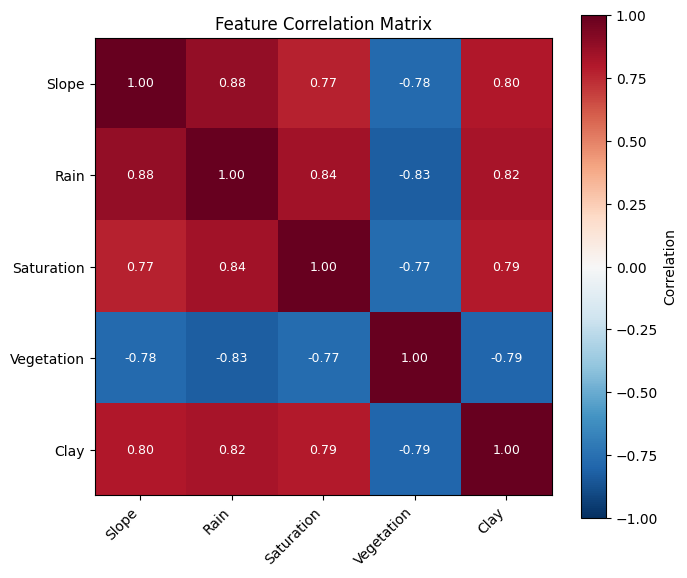

Features generated independently show moderate correlations due to class structure.
In real geotechnical data, slope and saturation would be more correlated.
Higher correlations = the naive assumption is more violated.


In [8]:
# ─────────────────────────────────────────────────────
# CHECK FEATURE CORRELATIONS
# ─────────────────────────────────────────────────────

corr = df[features].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))
short_names = ['Slope', 'Rain', 'Saturation', 'Vegetation', 'Clay']
ax.set_xticklabels(short_names, rotation=45, ha='right')
ax.set_yticklabels(short_names)

for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}',
                ha='center', va='center', fontsize=9,
                color='white' if abs(corr.values[i,j]) > 0.5 else 'black')

plt.colorbar(im, label='Correlation')
ax.set_title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

print("Features generated independently show moderate correlations due to class structure.")
print("In real geotechnical data, slope and saturation would be more correlated.")
print("Higher correlations = the naive assumption is more violated.")

---

## Part 7: Compare with Logistic Regression

Both Naive Bayes and Logistic Regression are **probabilistic classifiers** that output class probabilities. Let us compare them:

| Aspect | Naive Bayes | Logistic Regression |
|--------|------------|--------------------|
| Model type | Generative | Discriminative |
| Assumption | Feature independence | Linear decision boundary |
| Training speed | Very fast | Fast |
| Small data | Works well | May overfit |
| Correlated features | Can struggle | Handles better |
| Scaling needed | No | Yes |

In [9]:
# ─────────────────────────────────────────────────────
# COMPARE: Naive Bayes vs Logistic Regression
# ─────────────────────────────────────────────────────

# LR needs scaled features
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, random_state=45)
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)

# Cross-validation comparison
cv_nb = cross_val_score(GaussianNB(), X, y_encoded, cv=5, scoring='accuracy')
cv_lr = cross_val_score(LogisticRegression(max_iter=1000, random_state=45),
                        scaler.fit_transform(X), y_encoded, cv=5, scoring='accuracy')

print("Model Comparison:")
print(f"{'':20s} {'Test Acc':>10} {'CV Mean':>10} {'CV Std':>10}")
print("─" * 52)
print(f"{'Gaussian NB':<20s} {accuracy_score(y_test, y_pred_nb):>10.3f} "
      f"{cv_nb.mean():>10.3f} {cv_nb.std():>10.3f}")
print(f"{'Logistic Regression':<20s} {accuracy_score(y_test, y_pred_lr):>10.3f} "
      f"{cv_lr.mean():>10.3f} {cv_lr.std():>10.3f}")

print("\nBoth models perform well on this data because classes are well-separated.")

Model Comparison:
                       Test Acc    CV Mean     CV Std
────────────────────────────────────────────────────
Gaussian NB               1.000      1.000      0.000
Logistic Regression       1.000      0.988      0.025

Both models perform well on this data because classes are well-separated.


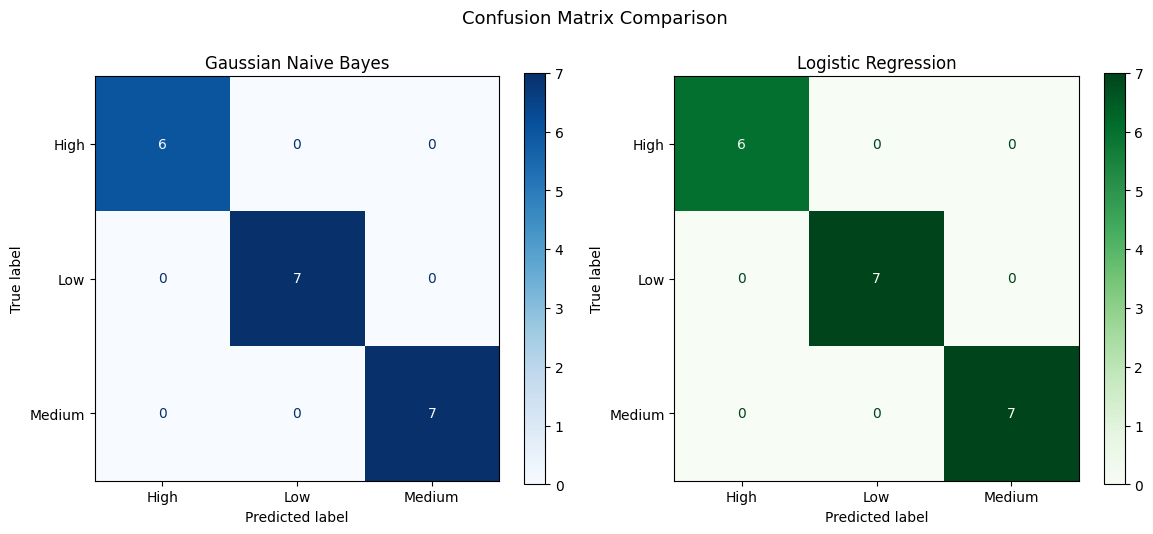

In [10]:
# ─────────────────────────────────────────────────────
# SIDE-BY-SIDE CONFUSION MATRICES
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_nb, display_labels=le.classes_,
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('Gaussian Naive Bayes')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, display_labels=le.classes_,
    cmap='Greens', ax=axes[1]
)
axes[1].set_title('Logistic Regression')

plt.suptitle('Confusion Matrix Comparison', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---

## Part 8: When NB Shines vs Struggles

Let us test NB with deliberately correlated features to see the independence assumption break down.

In [11]:
# ─────────────────────────────────────────────────────
# NB WITH CORRELATED FEATURES
# ─────────────────────────────────────────────────────

# Add a correlated feature: saturation_proxy = 0.8 * saturation + noise
X_corr = X.copy()
X_corr['sat_proxy'] = X_corr['soil_saturation'] * 0.8 + np.random.normal(0, 3, len(X))
X_corr['slope_proxy'] = X_corr['slope_angle'] * 0.9 + np.random.normal(0, 2, len(X))

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_corr, y_encoded, test_size=0.25, random_state=45, stratify=y_encoded
)

# NB with correlated features
gnb_corr = GaussianNB()
gnb_corr.fit(X_train_c, y_train_c)

# LR with correlated features
scaler_c = StandardScaler()
lr_corr = LogisticRegression(max_iter=1000, random_state=45)
lr_corr.fit(scaler_c.fit_transform(X_train_c), y_train_c)

print("Effect of Adding Correlated Features:")
print(f"\n{'Model':<20s} {'Original':>10} {'+ Correlated':>14}")
print("─" * 46)
print(f"{'Naive Bayes':<20s} {accuracy_score(y_test, y_pred_nb):>10.3f} "
      f"{gnb_corr.score(X_test_c, y_test_c):>14.3f}")
print(f"{'Logistic Regression':<20s} {accuracy_score(y_test, y_pred_lr):>10.3f} "
      f"{lr_corr.score(scaler_c.transform(X_test_c), y_test_c):>14.3f}")

print("\nInsight: NB can be affected by redundant correlated features because")
print("it counts the same information twice. LR handles this better.")
print("In practice, remove highly correlated features before using NB.")

Effect of Adding Correlated Features:

Model                  Original   + Correlated
──────────────────────────────────────────────
Naive Bayes               1.000          0.950
Logistic Regression       1.000          0.950

Insight: NB can be affected by redundant correlated features because
it counts the same information twice. LR handles this better.
In practice, remove highly correlated features before using NB.


---

## Part 9: Predict New Sites

In [12]:
# ─────────────────────────────────────────────────────
# PREDICT NEW INVESTIGATION SITES
# ─────────────────────────────────────────────────────

new_sites = pd.DataFrame({
    'slope_angle': [10, 28, 42, 18, 35],
    'rainfall_mm': [40, 110, 180, 65, 145],
    'soil_saturation': [25, 60, 85, 35, 72],
    'vegetation_cover': [80, 45, 15, 70, 30],
    'clay_content': [12, 32, 50, 20, 40]
})

preds = gnb.predict(new_sites)
probas = gnb.predict_proba(new_sites)

print("New Site Risk Predictions:")
print(f"{'Site':>5} {'Slope':>6} {'Rain':>6} {'Sat':>5} {'Veg':>5} {'Clay':>5} "
      f"{'Risk':>8} {'Confidence':>11}")
print("─" * 58)
for i, (_, row) in enumerate(new_sites.iterrows()):
    risk = le.classes_[preds[i]]
    conf = probas[i].max() * 100
    print(f"{i+1:5d} {row['slope_angle']:5.0f} {row['rainfall_mm']:5.0f} "
          f"{row['soil_saturation']:5.0f} {row['vegetation_cover']:4.0f} "
          f"{row['clay_content']:5.0f} {risk:>8s} {conf:10.1f}%")

print("\nNB provides probability-based risk assessment — great for quick screening.")

New Site Risk Predictions:
 Site  Slope   Rain   Sat   Veg  Clay     Risk  Confidence
──────────────────────────────────────────────────────────
    1    10    40    25   80    12      Low      100.0%
    2    28   110    60   45    32   Medium      100.0%
    3    42   180    85   15    50     High      100.0%
    4    18    65    35   70    20      Low       99.6%
    5    35   145    72   30    40     High      100.0%

NB provides probability-based risk assessment — great for quick screening.


---

## Practice Exercises

### Exercise 1: Vary Training Size
Train GaussianNB with 20%, 40%, 60%, 80% of the data. Plot accuracy vs training size. At what point does NB plateau? Compare with Logistic Regression.

### Exercise 2: Feature Importance
Train NB with one feature removed at a time. Which single feature removal hurts accuracy the most? That is the most important feature for hazard classification.

### Exercise 3: Binary Classification
Merge Medium and High into a single "Elevated Risk" class. Compare NB and LR on this binary problem. Does the simpler problem change which model wins?

In [13]:
# EXERCISE 1: Training size effect
# for frac in [0.2, 0.4, 0.6, 0.8]:
#     X_tr, _, y_tr, _ = train_test_split(X_train, y_train, train_size=frac)
#     gnb_tmp = GaussianNB().fit(X_tr, y_tr)
#     print(f"Train size {frac:.0%}: Acc = {gnb_tmp.score(X_test, y_test):.3f}")

In [14]:
# EXERCISE 2: Feature importance by removal
# for feat in features:
#     X_reduced = X_train.drop(columns=[feat])
#     gnb_tmp = GaussianNB().fit(X_reduced, y_train)
#     acc = gnb_tmp.score(X_test.drop(columns=[feat]), y_test)
#     print(f"Without {feat:20s}: Acc = {acc:.3f}")

In [15]:
# EXERCISE 3: Binary classification
# y_binary = np.where(y_encoded == 1, 0, 1)  # Low=0, Medium+High=1

---

## Key Takeaways

1. **Naive Bayes uses Bayes' theorem** with the assumption that features are independent given the class. It estimates a Gaussian distribution (mean, variance) for each feature in each class.

2. **NB is extremely fast** and works well with small datasets. It only estimates 2 parameters per feature per class — perfect for quick hazard screening with limited field data.

3. **NB gives probability outputs** for each class. This is valuable in engineering: knowing P(High Risk)=0.85 is more actionable than just "High Risk".

4. **The independence assumption can hurt** when features are correlated (slope and saturation often are). In such cases, Logistic Regression may perform better.

5. **NB does not require feature scaling** since it models each feature distribution separately. This is an advantage over distance-based methods like SVM.

---

## How This Connects to ML

| Today's Concept | ML Application |
|----------------|----------------|
| Bayes' theorem | Foundation of probabilistic ML |
| Prior probability | Class imbalance handling |
| Likelihood | Feature distribution modeling |
| Posterior probability | Prediction with confidence |
| Independence assumption | Model simplification tradeoff |
| Generative vs discriminative | Two approaches to classification |
| NB vs Logistic Regression | Choosing the right probabilistic model |
| Probability calibration | Reliable confidence estimates |

---

*Day 045 of 100 — Naive Bayes gives fast, probabilistic hazard predictions!*